In [3]:
# 1. 데이터 불러오기

from pathlib import Path # pathlib = 파일경로 조회 
                         # Path    = 파일경로 생성 및 조회 
import pandas as pd # padas = 표
import numpy as np  # numpy = 배열
import matplotlib.pyplot as plt # matplotlib = 그래프
import seaborn as sns # seaborn = 통계(그래프)

# 프로젝트 루트 경로
ROOT  = Path.cwd().resolve() # Path   = 파일경로 생성 및 조회
                             # .cwd() = 현재 경로 조회 --> C:\projects\projectAI\GangNaengI_AI\notebooks
                             # .resolve() = 현재 경로를 절대경로로 변경 

if ROOT.name == "notebooks":
  ROOT = ROOT.parent # 현재 경로의 상위 폴더를 가져와라
                     # 현재 폴더 = notebooks
                     # 상위 폴더 = GangNaengI_AI
                     # ROOT = C:\projects\projectAI\GangNaengI_AI
  
RAW = ROOT / "data" / "raw" # ROOT = C:\projects\projectAI\GangNaengI_AI\
                            # RAW  = C:\projects\projectAI\GangNaengI_AI\data\raw

# NHANES XPT 파일 읽기
# pd        = pandas
# .read_sas = SAS 데이터 파일 읽기
# RAW / ""  = 읽어올 파일 경로
# --> C:\projects\projectAI\GangNaengI_AI\data\raw\"파일명"
perio = pd.read_sas(RAW / "OHXPER_H.xpt", format="xport") # OHXPER_H.xpt = 치주 검사 관련 파일
demo = pd.read_sas(RAW / "DEMO_H.xpt", format="xport")    # DEMO_H.xpt   = 인구 통계 데이터 파일
smoking = pd.read_sas(RAW / "SMQ_H.xpt", format="xport")   # SMQ_H.xpt    = 흡연 설문 데이터 파일

# 데이터 크기 출력
# shape = 행과 열을 출력
print("치주검사: ", perio.shape) # perio의 행과 열 출력 --> ex) (5000, 30) == 5000행 30열
print("인구통계: ", demo.shape)
print("흡연: ", smoking.shape)

display(perio.head()) # display() = 주피터에서만 사용 가능
                      #           = 데이터를 표로 정리
                      # .head()   = 맨 앞 5개의 행만 반환

Matplotlib is building the font cache; this may take a moment.


치주검사:  (4669, 508)
인구통계:  (10175, 47)
흡연:  (7168, 32)


C:\Users\tempo\AppData\Local\Temp\ipykernel_10116\2579104986.py:31: Pandas4Warning: The default value of 'encoding' in read_sas is deprecated. In a future version the default will change from None to 'infer', and character columns will be decoded rather than returned as bytes (XPORT files record no encoding, so 'infer' means 'ISO-8859-1'). Pass encoding='infer' to adopt the future behavior, or encoding=None to keep the current one.
  smoking = pd.read_sas(RAW / "SMQ_H.xpt", format="xport")   # SMQ_H.xpt    = 흡연 설문 데이터 파일


,SEQN,OHDEXSTS,OHDPDSTS,OHDEXCLU,OHX02CJD,OHX02CJM,OHX02CJS,OHX02CJP,OHX02CJL,OHX02CJA,...,OHX31PCS,OHX31PCP,OHX31PCL,OHX31PCA,OHX31LAD,OHX31LAM,OHX31LAS,OHX31LAP,OHX31LAL,OHX31LAA
0,73557.0,1.0,1.0,2.0,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0
1,73558.0,1.0,1.0,2.0,-2.000000e+00,-1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0
2,73559.0,1.0,1.0,2.0,5.397605e-79,5.397605e-79,5.397605e-79,-1.000000e+00,-1.000000e+00,-1.000000e+00,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0
3,73561.0,1.0,1.0,2.0,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0
4,73562.0,1.0,1.0,2.0,5.397605e-79,5.397605e-79,5.397605e-79,-4.000000e+00,-4.000000e+00,-3.000000e+00,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0


In [5]:
# 2. 데이터 3개 합치기

# 인구통계
demo_cols = [ # 실제 데이터를 저장하는게 아닌 열의 이름만 저장함 
#               즉 demo에 열이 50개가 있어도 [] 안에 3개 뿐이라 열 3개만 선택함
  "SEQN",      # NHANES 참가자 식별번호
  "RIDAGEYR",  # 참가자의 나이 - 연도기준
  "RIAGENDR", # 참가자의 성별 --> 보통 1=남자 2=여자로 기본 세팅
]

# 흡연
smoking_cols = [
  "SEQN",   # NHANES 참가자 식별번호
  "SMQ020", # 평생 담배 100개비 이상 흡연 하였는가
  "SMQ040", # 현재 흡연 빈도 --> 요즘도 자주 피는지 or 담배 가끔 피는지
]

# 참가자 번호 기준으로 결합
df = perio.merge( # df     = 데이터프레임
#                   .merge = 데이터프레임 두개를 공통 열(SEQN) 기준으로 결합
  demo[demo_cols],# 인구통계(demo)의 열 3가지만 선택(SEQN, RIDAGEYR, RIAGENDER)
  on="SEQN",      # on = SEQN이라는 열을 기준으로 결합하겠다
  how="left",     # left join
  validate="one_to_one" # 중복되는 데이터 확인 --> perio에 101이 두개 있다면 MergeError
)
print("결합된 데이터 크기: ", df.shape) # df.shape = 결합된 df의 행과 열 출력

display(df.head()) # display = 데이터를 표로 정리(주피터에서만 사용 가능)
                   # head()  = 결합된 df의 맨 앞 5개만 출력

결합된 데이터 크기:  (4669, 510)


,SEQN,OHDEXSTS,OHDPDSTS,OHDEXCLU,OHX02CJD,OHX02CJM,OHX02CJS,OHX02CJP,OHX02CJL,OHX02CJA,...,OHX31PCL,OHX31PCA,OHX31LAD,OHX31LAM,OHX31LAS,OHX31LAP,OHX31LAL,OHX31LAA,RIDAGEYR,RIAGENDR
0,73557.0,1.0,1.0,2.0,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,69.0,1.0
1,73558.0,1.0,1.0,2.0,-2.000000e+00,-1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,54.0,1.0
2,73559.0,1.0,1.0,2.0,5.397605e-79,5.397605e-79,5.397605e-79,-1.000000e+00,-1.000000e+00,-1.000000e+00,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,72.0,1.0
3,73561.0,1.0,1.0,2.0,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,9.900000e+01,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,73.0,2.0
4,73562.0,1.0,1.0,2.0,5.397605e-79,5.397605e-79,5.397605e-79,-4.000000e+00,-4.000000e+00,-3.000000e+00,...,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,56.0,1.0


In [6]:
# 3. 컬럼 및 자료형 분석하기
#    즉 데이터에 어떤 변수가 있는가

# 전체 컬럼 확인
print(df.columns.tolist()) # df       = 데이터프레임
                           # columns  = 모든 열(컬럼)
                           # tolist() = 컬럼을 파이썬 리스트로 변환
                           # 요약: 모든 컬럼명 제시해
                           # ex) SEQN RIDAGEYR ... 등등

# 데이터 타입 확인
print(df.dtypes.value_counts()) # dtypes = 컬럼 타입 확인
                                # value_counts() = 동일한 값 몇 개 있는지 확인
                                # 요약: 같은 타입 몇개 있냐 
                                # ex) int64 3개 object 1개
                                # 타입 종류 - int64 / float64 / bool / object / datetime64

# 기본 통계량 확인
print(df.describe()) # 기초 통계량 확인
                     # 기초 통계량: count / mean / std / min / 25% / 50% / 75% / max

# 결측지 비율 확인
missing = (
  df.isna().mean() * 100 # isna() = 값이 결측치 인가 ex) NaN None pd.NA
                         # 값이 결측치면 True라고 나옴
                         # .mean * 100 = 백분율
                         # False가 3개 True가 1개라면 결측치 비율이 25% 이런거 계산할려고 쓴 코드
).sort_values(ascending=False) # .sort_values()  = 값을 기준으로 정렬하라
                               # ascending=Ture  = 오름차순
                               # ascending=False = 내림차순

display(missing.head(20)) # display   = 데이터를 표로 정리
                          # .head(20) = 맨 앞 20개만 ㅜㄹ력

# 확인해야 할 것
# 1. 어떤 컬럼에 결측치가 많은가
# 2. 숫자형 변수는 뭔가
# 3. 실제 모델 입력으로 사용 가능한 변수는 무엇인가

# 주의사항
# NHANES에서 99는 측정 불가라는 뜻임(특수코드 중 하나)
# --> 즉 단순 99라는 숫자로 해석 하면 안되니 "데이터 문서의 코드북" 확인 필수

# 참고
# NHANES = National Health and Nutrition Examination Survey
# 미국 국민건강영양조사
# xpt 파일마다 _H가 붙은 이유는 2013~2014년도 자료라는 뜻

# NHANES 특수코드
# 7   refused     응답거부
# 77  refused     응답거부
# 777 refused     응답거부
# 
# 9   don't know  모름
# 99  don't know  모름
# 999 don't know  모름
#
# NaN missing     결측값

['SEQN', 'OHDEXSTS', 'OHDPDSTS', 'OHDEXCLU', 'OHX02CJD', 'OHX02CJM', 'OHX02CJS', 'OHX02CJP', 'OHX02CJL', 'OHX02CJA', 'OHX02PCD', 'OHX02PCM', 'OHX02PCS', 'OHX02PCP', 'OHX02PCL', 'OHX02PCA', 'OHX02LAD', 'OHX02LAM', 'OHX02LAS', 'OHX02LAP', 'OHX02LAL', 'OHX02LAA', 'OHX03CJD', 'OHX03CJM', 'OHX03CJS', 'OHX03CJP', 'OHX03CJL', 'OHX03CJA', 'OHX03PCD', 'OHX03PCM', 'OHX03PCS', 'OHX03PCP', 'OHX03PCL', 'OHX03PCA', 'OHX03LAD', 'OHX03LAM', 'OHX03LAS', 'OHX03LAP', 'OHX03LAL', 'OHX03LAA', 'OHX04CJD', 'OHX04CJM', 'OHX04CJS', 'OHX04CJP', 'OHX04CJL', 'OHX04CJA', 'OHX04PCD', 'OHX04PCM', 'OHX04PCS', 'OHX04PCP', 'OHX04PCL', 'OHX04PCA', 'OHX04LAD', 'OHX04LAM', 'OHX04LAS', 'OHX04LAP', 'OHX04LAL', 'OHX04LAA', 'OHX05CJD', 'OHX05CJM', 'OHX05CJS', 'OHX05CJP', 'OHX05CJL', 'OHX05CJA', 'OHX05PCD', 'OHX05PCM', 'OHX05PCS', 'OHX05PCP', 'OHX05PCL', 'OHX05PCA', 'OHX05LAD', 'OHX05LAM', 'OHX05LAS', 'OHX05LAP', 'OHX05LAL', 'OHX05LAA', 'OHX06CJD', 'OHX06CJM', 'OHX06CJS', 'OHX06CJP', 'OHX06CJL', 'OHX06CJA', 'OHX06PCD', 'OHX06P

OHX22CJD    14.692654
OHX22CJM    14.692654
OHX22CJS    14.692654
OHX22CJP    14.692654
OHX22CJL    14.692654
OHX22CJA    14.692654
OHX22PCD    14.692654
OHX22PCM    14.692654
OHX22PCS    14.692654
OHX22PCP    14.692654
OHX22PCL    14.692654
OHX22PCA    14.692654
OHX22LAD    14.692654
OHX22LAM    14.692654
OHX22LAS    14.692654
OHX22LAP    14.692654
OHX22LAL    14.692654
OHX22LAA    14.692654
OHX27LAM    14.692654
OHX27LAD    14.692654
dtype: float64

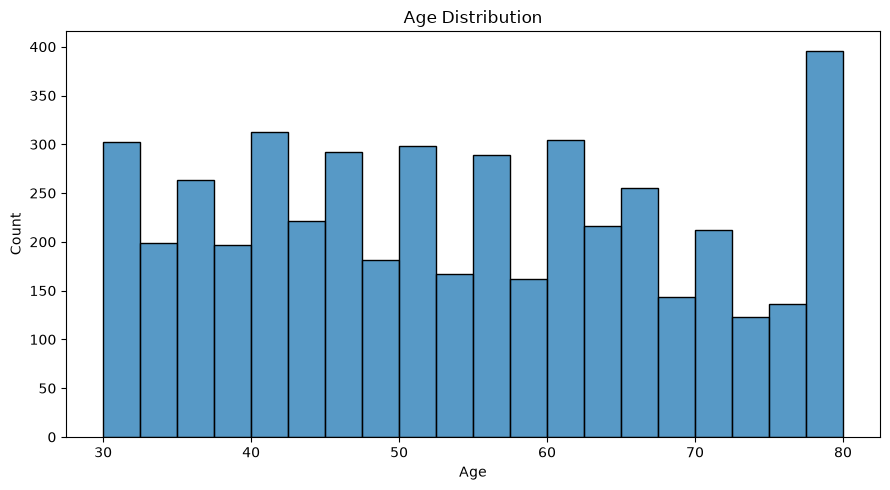

In [7]:
# 4-1 데이터 분포 시각화(EDA)
# 연령 분포

# 그래프 크기 설정
plt.figure(figsize=(9, 5)) # plt        = matplotlib.pyplot의 별칭(그래프 만들겠다는 것)
                           # .figure()  = 그래프 생성 함수
                           # figsize=() = 그래프 크기 지정 매개변수
                           # ex) (9, 5) --> 가로 9인치 + 세로 5인치  

sns.histplot( # sns = SeaBorn 별칭(통계 그래프 만들겠다는 뜻)
  data=df,    # data = 아까 그 데이터프레임(3개 합친거)
  x="RIDAGEYR", # x축 변수 = RIDAGEYR(참가자 연령)
  bins=20       # 구간을 20개로 나누겠다 
)               # ex) 0~100세를 20개로 나눔 --> 0 / 5 / 10 ... / 100

plt.title("Age Distribution") # .title() = 그래프 제목
plt.xlabel("Age")   # .xlabel() = x축 이름 설정
plt.ylabel("Count") # .ylabel() = y축 이름 설정
plt.tight_layout()  # .tight_layout() = 그래프 요소 배치 자동화
                    # --> 제목이나 x축 y축 등이 너무 많을 때 그래프 밖으로 안삐져 나가게 여백 자동 조절
plt.show() # 그래프 출력

# 연령분표 확인하는 이유
# 1. 특정 연령대에 데이터가 집중 되는가 --> 30대 이후 치주염 증가 등등 
# 2. 젊은사람과 노인의 데이터가 고른가  --> 젊은이 10명 노인 10명 ... 등등
# 3. 일부 연령대에 데이터가 너무 적은가 --> 젊은이 1명  노인 100명 ...등등

OHDPDSTS
1.0    3982
3.0     611
2.0      76
Name: count, dtype: int64


NameError: name 'pt' is not defined

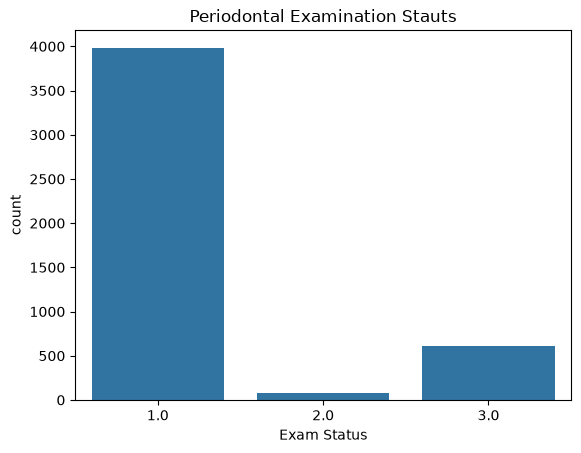

In [ ]:
# 4-2 데이터 분포 시각화(EDA)
# 치주검사 완료 여부

print(df["OHDPDSTS"].value_counts(dropna=False)) # df["OHDPDSTS"]  = 데이터프레임 중 OHDPDSTS 컬럼 찾아라
                                                 # .value_counts() = 각 값이 몇번 나타나는지 조회하는 메서드
                                                 # dropna = 결측값을 집계에서 제외할지 말지
                                                 # dropna(True)  = 결측값 미포함(기본값)
                                                 # dropna(False) = 결측값도 포함

sns.countplot( # sns = SeanBorn의 라이브러리
               # countplot() = 범주별 데이터 개수를 그래프로 표시 ex) 치주 검사 상태
  data=df,
  x="OHDPDSTS" # x축은 OHDPDSTS
)

plt.title("Periodontal Examination Stauts") # 그래프 제목
plt.xlabel("Exam Status") # x축 이름
plt.ylabel("Count") # y축 이름
plt.show() # 그래프 출력

# 참고
# 1. OHDPDSTS가 1인 경우: 검사 완료
# 1. OHDPDSTS가 2인 경우: 일부 검사 완료
# 1. OHDPDSTS가 3인 경우: 검사 안함

In [ ]:
# 4-3 데이터 분포 시각화(EDA)
# 치주낭 깊이(PD) 분포

# 치주검사 완료 대상자
complete = df[df["OHDPDSTS"] == 1].copy() # 치주검사 컬럼은 OHDPDSTS 
                                          # 이 컬럼 중 검사 상태가 1인 것만 선택
                                          # 선택한 데이터 복사해서 complete에 저장

# 치주낭 깊이 컬럼 탐색
pd_cols = [
  col for col in complete.columns # col을 반복하여 complete 컬럼들 값 하나씩 받아라
  if col.startswith("OHX") and "PC" in col # 근데 받을 때 조건 있음
]                                          # .startswith() = 특정 문자열로 시작할 것
                                           # 즉 OHX로 시작하면서 PC라는 문자열도 포함된 컬럼만 col에 담아라


print("PD 컬럼 개수: ", len(pd_cols)) # 컬럼 개수 출력

# 측정 불가 코드 등은 시각화에 제외
pd_values = complete[pd_cols].where( # .where() = 조건에 맞지 않는 값은 NaN 취급
    (complete[pd_cols] >= 0) & # 0  이상인가
    (complete[pd_cols] <= 20)  # 20 이하인가
)                              # 0 ~ 20 사이만

# DF를 Serise로 변환하라
values = pd_values.stack() # .stack() = 컬럼 방향의 데이터를 행 방향으로 변환

plt.figure(figsize=(9, 5)) # # plt      = matplotlib.pyplot의 별칭(그래프 만들겠다는 것)
                           # .figure()  = 그래프 생성 함수
                           # figsize()  = 그래프 크기 설정
                           # ex) (9, 5) --> 가로 9인치 세로 5인치
# 히스토그램 생성                           
sns.histplot(values, bins=20) # sns = SeaBorn 라이브러리
                              # .histplot() = 히스토그램 생성
                              # values  = 치주낭 깊이 측정값들(Series)
                              # bins=20 = 값의 범위를 20개 단위로 분할

plt.title("Periodontal Pcoket Depth Distribution") # 그래프 제목
plt.xlabel("Pocket Depth (mm)") # x축 이름
plt.ylabel("Count") # y축 이름
plt.tight_layout() # 그래프 여백 자동 조절
plt.show() # 그래프 출력

In [ ]:
# 5. 분석 결과 저장

# 전처리 데이터 저장
PROCESSED = ROOT / "data" / "processed" # PROCESSED = C:\projects\projectAI\GangNaengI_AI\data\processed
PROCESSED.mkdir(parents=True, exist_ok=True) # .mkdir = 폴더 생성
                                             # parents=True  = 상위 폴더도 함께 생성
                                             # exist_ok=True = 폴더가 이미 존재해도 오류 발생 x(있으면 생성 안하고 그대로)

# 통합 데이터 저장
df.to_csv( # .to_csv() = 데이터프레임을 CSV 파일로 저장하는 Pandas 메서드
  PROCESSED / "nhanes_merged.csv", # CSV 저장 경로: C:\projects\projectAI\GangNaengI_AI\data\processed\nhanes_merged.csv 
  index=False # False = 행 인덱스를 저장하지 않음
)             # True  = 행 인덱스를 저장

# 결측지 분석 결과 저장
missing.to_csv(
  PROCESSED / "missing_report.csv",
  header=["missing_rate"] # header = CSV에 저장할 열 제목 지정하는 매개변수
)                         # missing_rate = 결측치 비율 컬럼 제목(리스트)

print("day01 - 데이터 수집 및 EDA 처리 완료") 